# 02. 탐색적 데이터 분석 (EDA)

**입력**: `dataSet/student_clean.csv` (2,737행)
**출력**: `out/02_*.csv`, `out/02_*.png`

회귀에 들어가기 전에 변수 하나하나가 어떻게 생겼는지 본다.
1. 연속형 — 평균과 중앙값이 비슷한지(상대편차), 왜도·첨도(로그변환 필요 여부), 이상치 비율
2. 명목형 — 특정 범주에 쏠려 있지 않은지 (더미 코딩 시 희소 범주 문제)
3. 시각화 — 각 변수와 기말고사 점수의 관계, 직선이 아닌 패턴 찾기

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager

# 한글 폰트 (저장소에 같이 들어 있는 파일)
font_manager.fontManager.addfont('NotoSansKR-Regular.ttf')
plt.rcParams['font.family'] = font_manager.FontProperties(fname='NotoSansKR-Regular.ttf').get_name()
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.width', 160)

df = pd.read_csv('dataSet/student_clean.csv')
TARGET = 'final_exam_score'

cat_cols = ['gender', 'city_type', 'doomscrolling_before_sleep', 'mental_state', 'learning_style', 'career_goal']
num_cols = [c for c in df.columns if c not in cat_cols + [TARGET]]
print(len(num_cols), '개 연속형 /', len(cat_cols), '개 명목형')

23 개 연속형 / 6 개 명목형


## 1. 연속형 변수 기술통계

- **상대편차** = (평균 − 중앙값) / 중앙값. 0에 가까우면 평균과 중앙값이 비슷하다.
- **왜도** |값| < 0.5 면 대칭, **첨도** < 0 이면 정규분포보다 완만. 둘 다 만족하면 로그변환이 필요 없다.
- **이상치**는 IQR × 1.5 밖의 값 비율.

In [2]:
def outlier_ratio(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()

desc = pd.DataFrame({
    '평균': df[num_cols + [TARGET]].mean(),
    '중앙값': df[num_cols + [TARGET]].median(),
    '표준편차': df[num_cols + [TARGET]].std(),
    '왜도': df[num_cols + [TARGET]].skew(),
    '첨도': df[num_cols + [TARGET]].kurt(),
    '이상치비율': df[num_cols + [TARGET]].apply(outlier_ratio),
})
desc['상대편차'] = (desc['평균'] - desc['중앙값']) / desc['중앙값']
desc = desc.round(3)
desc.to_csv('out/02_연속형_기술통계.csv')
desc

,평균,중앙값,표준편차,왜도,첨도,이상치비율,상대편차
age,19.029,19.0,2.559,0.016,-1.209,0.000,0.002
study_hours_per_day,3.955,4.0,1.474,-0.005,-0.253,0.002,-0.011
deep_work_sessions,3.510,4.0,2.294,0.004,-1.239,0.000,-0.122
assignment_completion_rate,69.948,70.0,17.560,-0.009,-1.193,0.000,-0.001
attendance_percentage,74.498,74.0,14.441,0.043,-1.151,0.000,0.007
social_media_hours,2.881,2.9,1.475,0.118,-0.384,0.002,-0.006
notification_distractions,61.869,62.0,33.198,-0.022,-1.225,0.000,-0.002
ai_tool_usage_hours,1.531,1.5,0.922,0.342,-0.108,0.007,0.020
gaming_hours,1.996,1.9,1.351,0.390,-0.442,0.002,0.050
stress_level,5.551,6.0,2.895,-0.024,-1.225,0.000,-0.075


In [3]:
print('|상대편차| > 0.1 :', desc.index[desc['상대편차'].abs() > 0.1].tolist())
print('|왜도| >= 0.5  :', desc.index[desc['왜도'].abs() >= 0.5].tolist())
print('첨도 >= 0      :', desc.index[desc['첨도'] >= 0].tolist())
print('이상치 >= 1%   :', desc.index[desc['이상치비율'] >= 0.01].tolist())

|상대편차| > 0.1 : ['deep_work_sessions', 'caffeine_intake']
|왜도| >= 0.5  : []
첨도 >= 0      : []
이상치 >= 1%   : []


평균과 중앙값이 눈에 띄게 다른 변수는 `deep_work_sessions`(−0.12)와 `caffeine_intake`(0.17) 둘뿐이다.
모든 연속형 변수가 대칭(|왜도| < 0.5)이고 완만(첨도 < 0)해서 로그변환은 하지 않는다.
이상치도 전부 1% 미만이다. 합성 데이터라 분포가 고르게 만들어진 것으로 보인다.

## 2. 명목형 변수 분포

In [4]:
tables = []
for c in cat_cols:
    t = df[c].value_counts().rename('count').to_frame()
    t['ratio'] = (t['count'] / len(df)).round(3)
    t.index = pd.MultiIndex.from_product([[c], t.index], names=['변수', '범주'])
    tables.append(t)
cat_table = pd.concat(tables)
cat_table.to_csv('out/02_명목형_분포.csv')
cat_table

count  ratio
변수                         범주                       
gender                     Female        1388  0.507
                           Male          1349  0.493
city_type                  Rural          927  0.339
                           Semi-Urban     921  0.336
                           Urban          889  0.325
doomscrolling_before_sleep 0             1380  0.504
                           1             1357  0.496
mental_state               Distracted     718  0.262
                           Burnout        691  0.252
                           Focused        668  0.244
                           Balanced       660  0.241
learning_style             Visual         718  0.262
                           Practical      696  0.254
                           Reading        662  0.242
                           Audio          661  0.242
career_goal                Arts           582  0.213
                           Medical        575  0.210
                           Engineering    539  0.197
                           Business       534  0.195
                           Research       507  0.185

In [5]:
# 변수별 최대 범주 비율 − 최소 범주 비율
gap = cat_table.groupby('변수')['ratio'].agg(lambda r: r.max() - r.min()).round(3)
print(gap)

변수
career_goal                   0.028
city_type                     0.014
doomscrolling_before_sleep    0.008
gender                        0.014
learning_style                0.020
mental_state                  0.021
Name: ratio, dtype: float64


6개 변수 모두 최대·최소 범주 비율 차이가 5% 이내다. 더미 코딩해도 표본이 너무 적은 범주는 없다.

## 3. 연속형 변수 × 기말고사 점수 산점도

23개 변수를 한 장에 그린다. 점수는 정수라 겹치는 점이 많으니 투명도를 준다.

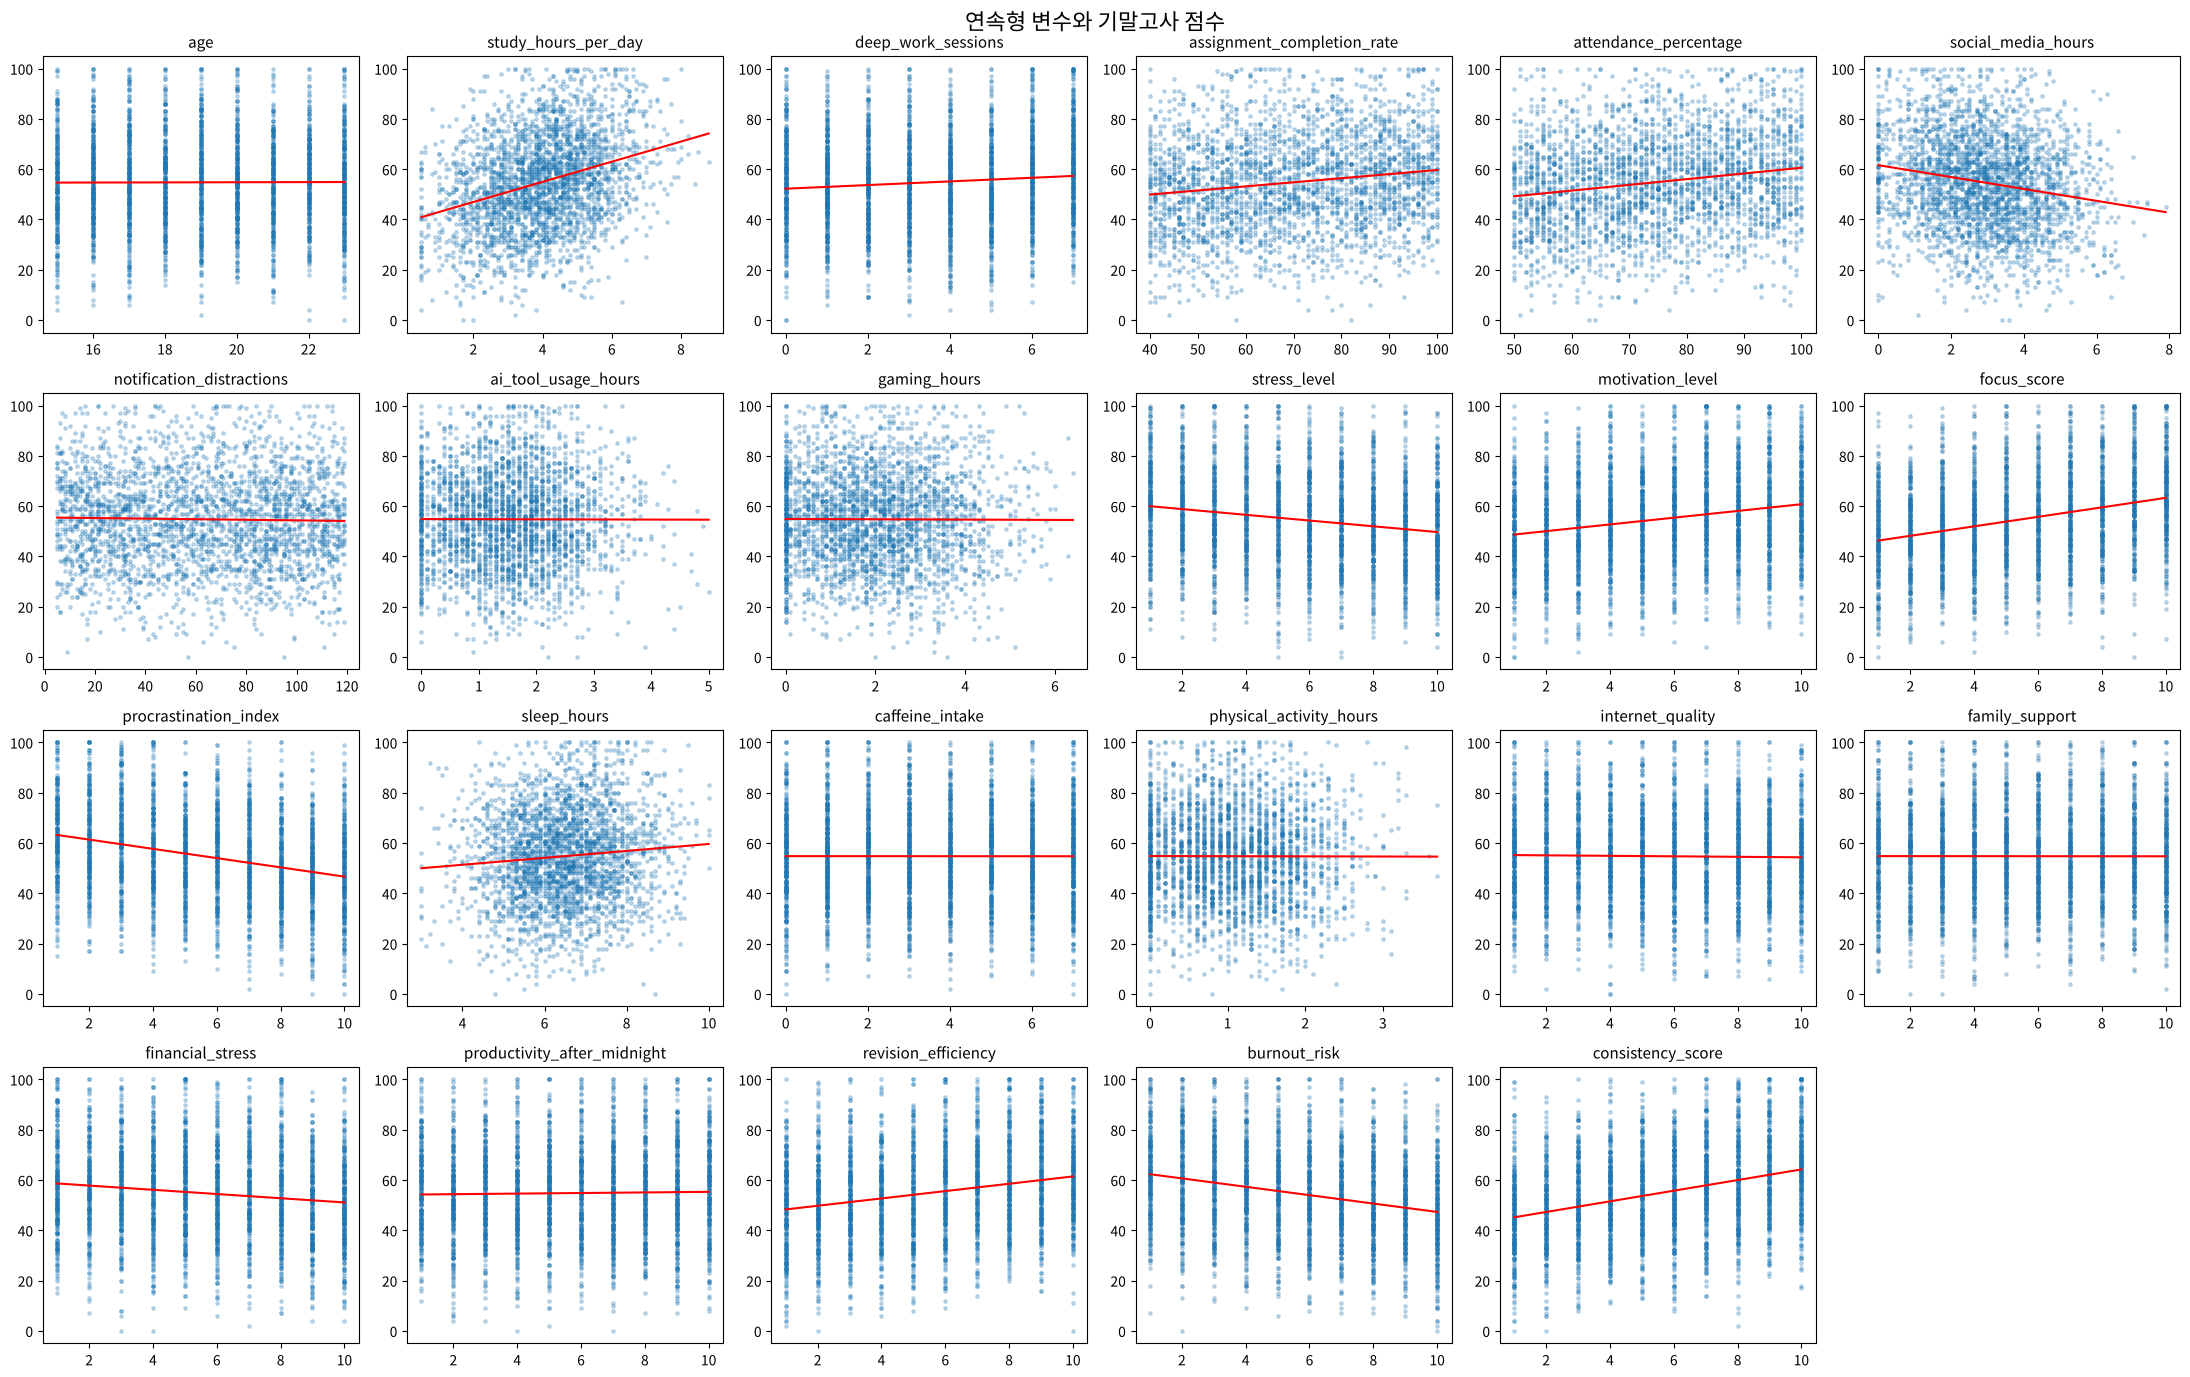

In [6]:
fig, axes = plt.subplots(4, 6, figsize=(22, 14))
for ax, c in zip(axes.flat, num_cols):
    ax.scatter(df[c], df[TARGET], s=6, alpha=0.25)
    # 추세선 (1차 다항식)
    coef = np.polyfit(df[c], df[TARGET], 1)
    xs = np.linspace(df[c].min(), df[c].max(), 50)
    ax.plot(xs, np.polyval(coef, xs), color='red', lw=1.5)
    ax.set_title(c, fontsize=11)
    ax.set_ylabel('')
for ax in axes.flat[len(num_cols):]:
    ax.axis('off')
fig.suptitle('연속형 변수와 기말고사 점수', fontsize=16)
fig.tight_layout()
fig.savefig('out/02_산점도_연속형.png', dpi=120)
plt.show()

count    2737.00
mean       54.76
std        18.64
min         0.00
25%        42.00
50%        55.00
75%        67.00
max       100.00
Name: final_exam_score, dtype: float64
100점 비율: 0.8%  / 0점 비율: 0.1%


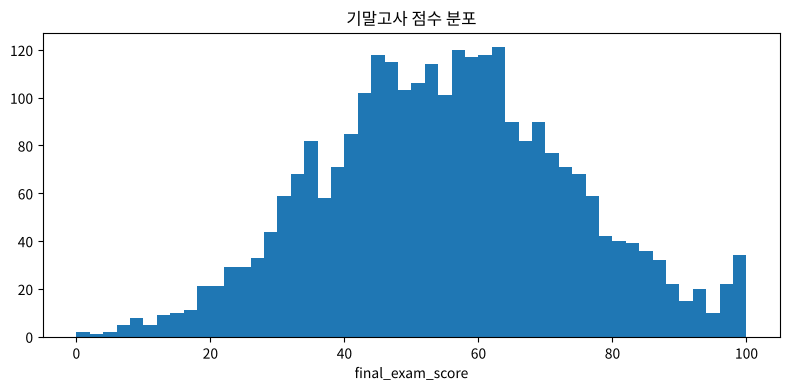

In [7]:
# 점수 분포 — 100점에 몰려 있는지 (천장효과)
print(df[TARGET].describe().round(2))
print('100점 비율:', f"{(df[TARGET] == 100).mean():.1%}", ' / 0점 비율:', f"{(df[TARGET] == 0).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df[TARGET], bins=50)
ax.set_title('기말고사 점수 분포')
ax.set_xlabel('final_exam_score')
fig.tight_layout()
fig.savefig('out/02_점수분포.png', dpi=120)
plt.show()

꾸준함·집중도·공부시간은 올라가는 경향, 미루기 지수는 내려가는 경향이 보인다.
점수는 0~100으로 잘려 있다. 100점을 넘을 학생은 100점으로 눌리고(천장효과), 선형회귀는 100점 이상도 예측하므로
양 끝에서 예측이 체계적으로 어긋날 수 있다. 04의 잔차 플롯에서 다시 확인하고 한계로 기록한다.

## 4. 직선으로 설명되지 않는 변수 두 개

산점도만으로는 보이지 않는 패턴을 **값별 평균 점수**로 확인한다.
- `deep_work_sessions`(0~7회): 횟수가 늘수록 점수가 일정하게 오르는가, 아니면 어느 구간에서 뛰는가?
- `physical_activity_hours`: 0시간에 몰려 있는 집단이 따로 있는가?

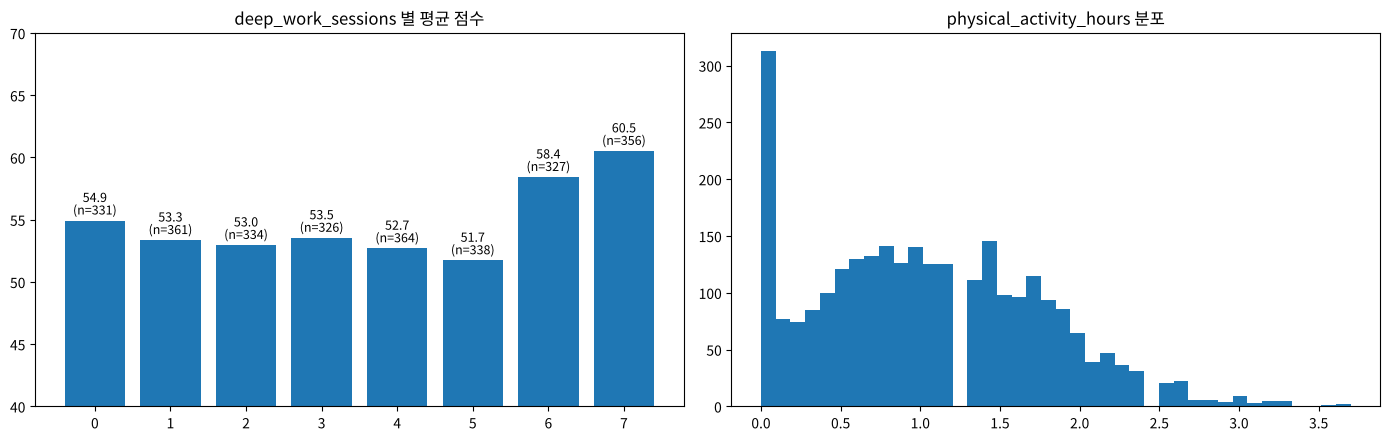

                     mean  count
deep_work_sessions              
0                   54.92    331
1                   53.35    361
2                   52.95    334
3                   53.53    326
4                   52.69    364
5                   51.72    338
6                   58.42    327
7                   60.51    356
신체활동 0시간 비율: 11.4%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

g = df.groupby('deep_work_sessions')[TARGET].agg(['mean', 'count'])
axes[0].bar(g.index, g['mean'])
axes[0].set_ylim(40, 70)
axes[0].set_title('deep_work_sessions 별 평균 점수')
for x, (m, n) in g.iterrows():
    axes[0].text(x, m + 0.5, f'{m:.1f}\n(n={int(n)})', ha='center', fontsize=9)

axes[1].hist(df['physical_activity_hours'], bins=40)
axes[1].set_title('physical_activity_hours 분포')
fig.tight_layout()
fig.savefig('out/02_비선형_후보.png', dpi=120)
plt.show()

print(g.round(2))
print('신체활동 0시간 비율:', f"{(df['physical_activity_hours'] == 0).mean():.1%}")

- `deep_work_sessions`: 0~5회는 평균이 거의 같고 6·7회에서 올라간다. "1회 늘면 점수가 B점 오른다"는 직선 가정이 안 맞는다.
  → 03에서 0~5회 / 6~7회 두 집단으로 나눠 차이가 유의한지 검정하고, 04에서 더미변수로 넣은 모형과 비교한다.
- `physical_activity_hours`: 0시간이 전체의 11%로 따로 뭉쳐 있다 (연속 분포에서 떨어진 덩어리).
  → 0시간 / 0시간 초과 두 집단으로 나눠 검정한다.

## 5. 명목형 변수 × 기말고사 점수 박스플롯

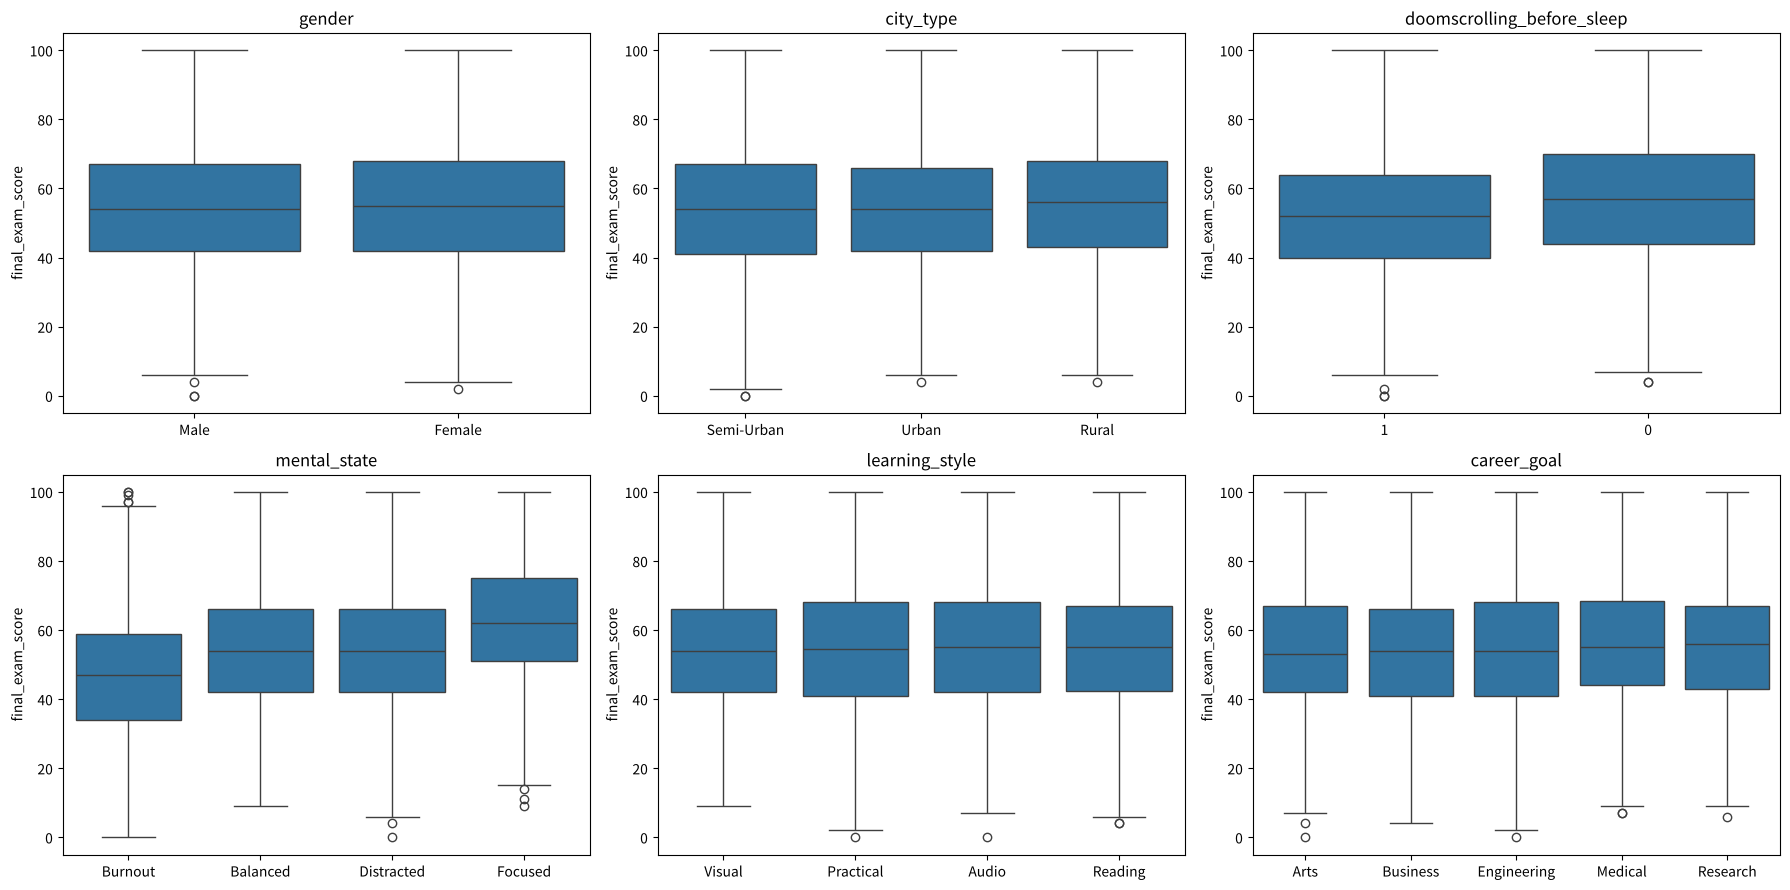

,median,mean,count
mental_state,,,
Balanced,54.0,54.63,660
Burnout,47.0,46.90,691
Distracted,54.0,54.49,718
Focused,62.0,63.31,668


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.flat, cat_cols):
    order = df.groupby(c)[TARGET].median().sort_values().index
    sns.boxplot(data=df, x=c, y=TARGET, order=order, ax=ax)
    ax.set_title(c)
    ax.set_xlabel('')
fig.tight_layout()
fig.savefig('out/02_박스플롯_명목형.png', dpi=120)
plt.show()

df.groupby(cat_cols[3])[TARGET].agg(['median', 'mean', 'count']).round(2)

취침 전 스마트폰을 **안 하는** 집단과 심리상태가 **Focused**인 집단의 중앙값이 높아 보인다.
눈에 보이는 차이가 우연인지는 03에서 검정한다.